In [ ]:
import kagglehub
import os

# Get the path to the cached dataset folder
dataset_dir = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

print("Dataset is stored in:", dataset_dir)
print("\nContents of the directory:")
for item in os.listdir(dataset_dir):
    print(f"- {item}")

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dataset is stored in: /kaggle/input/skin-cancer-mnist-ham10000

Contents of the directory:
- hmnist_8_8_RGB.csv
- hmnist_28_28_RGB.csv
- HAM10000_images_part_1
- ham10000_images_part_1
- hmnist_8_8_L.csv
- HAM10000_images_part_2
- ham10000_images_part_2
- hmnist_28_28_L.csv
- HAM10000_metadata.csv


In [ ]:
import os

for root, dirs, files in os.walk(dataset_dir):
    print(root, "→", len(files), "files")

/kaggle/input/skin-cancer-mnist-ham10000 → 5 files
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_1 → 5000 files
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_1 → 5000 files
/kaggle/input/skin-cancer-mnist-ham10000/HAM10000_images_part_2 → 5015 files
/kaggle/input/skin-cancer-mnist-ham10000/ham10000_images_part_2 → 5015 files


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

# Set a random seed for complete reproducibility across runs
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Define the root input directory in Kaggle
INPUT_DIR = Path("/kaggle/input")

# Find the metadata CSV file automatically
metadata_files = list(INPUT_DIR.rglob("HAM10000_metadata.csv"))
if not metadata_files:
    metadata_files = list(INPUT_DIR.rglob("*metadata*.csv"))
if not metadata_files:
    raise FileNotFoundError("Metadata CSV not found. Please click 'Add Input' in Kaggle and add HAM10000.")

METADATA_PATH = metadata_files[0]

# Find all dermoscopic images (.jpg) in the input directory
image_files = list(INPUT_DIR.rglob("*.jpg"))

print(f"Metadata found at: {METADATA_PATH}")
print(f"Total image files found: {len(image_files)}")

Metadata found at: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Total image files found: 20030


In [ ]:
# Load the main metadata CSV file
df = pd.read_csv(METADATA_PATH)

# Create a mapping dictionary from image_id (without extension) to absolute file path
image_map = {img.stem: str(img) for img in image_files}

# Map each row's image_id to its corresponding file path
df["image_path"] = df["image_id"].astype(str).map(image_map)

# Drop any rows where the image file couldn't be located on disk
df = df.dropna(subset=["image_path"]).copy()

print("Dataset shape after mapping images:", df.shape)
print(df.head())

Dataset shape after mapping images: (10015, 8)
     lesion_id      image_id   dx dx_type   age   sex localization  \
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp   
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp   
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp   
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp   
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear   

                                          image_path  
0  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
1  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
2  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
3  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
4  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate image IDs found:", df["image_id"].duplicated().sum())

print("\nClass distribution (Diagnostic Categories):")
print(df["dx"].value_counts())
print("Total number of classes:", df["dx"].nunique())

Missing values per column:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
image_path       0
dtype: int64

Duplicate image IDs found: 0

Class distribution (Diagnostic Categories):
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Total number of classes: 7


In [ ]:
# Convert patient age to a numeric format, forcing parsing errors to NaN
df["age"] = pd.to_numeric(df["age"], errors="coerce")

# Standardize categorical text attributes by filling missing values
df["sex"] = df["sex"].fillna("unknown").astype(str)
df["localization"] = df["localization"].fillna("unknown").astype(str)

# Set up group splitting criteria: prioritize patient_id if available to prevent patient-level leakage
if "patient_id" in df.columns:
    df["group_id"] = df["patient_id"].fillna(df["lesion_id"])
else:
    df["group_id"] = df["lesion_id"]

print("Dataset features and group IDs prepared successfully!")
print(df[["image_id", "dx", "age", "sex", "group_id", "image_path"]].head())

Dataset features and group IDs prepared successfully!
       image_id   dx   age   sex     group_id  \
0  ISIC_0027419  bkl  80.0  male  HAM_0000118   
1  ISIC_0025030  bkl  80.0  male  HAM_0000118   
2  ISIC_0026769  bkl  80.0  male  HAM_0002730   
3  ISIC_0025661  bkl  80.0  male  HAM_0002730   
4  ISIC_0031633  bkl  75.0  male  HAM_0001466   

                                          image_path  
0  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
1  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
2  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
3  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  
4  /kaggle/input/skin-cancer-mnist-ham10000/ham10...  


In [ ]:
# Step A: Split into Train+Validation (80%) and Test (20%) while keeping groups intact
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(splitter.split(df, df["dx"], groups=df["group_id"]))

trainval_df = df.iloc[trainval_idx].copy()
test_df = df.iloc[test_idx].copy()

# Step B: Split Train+Validation further into Training (~64%) and Validation (~16%)
splitter2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter2.split(trainval_df, trainval_df["dx"], groups=trainval_df["group_id"]))

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

print(f"Training samples:   {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Testing samples:    {len(test_df)}")

Training samples:   6409
Validation samples: 1592
Testing samples:    2014


Verification passed: No group overlap detected across splits!

Class distribution summary:
       Train  Validation  Test
dx                            
akiec    208          51    68
bcc      343          71   100
bkl      730         164   205
df        79          14    22
mel      728         163   222
nv      4248        1094  1363
vasc      73          35    34


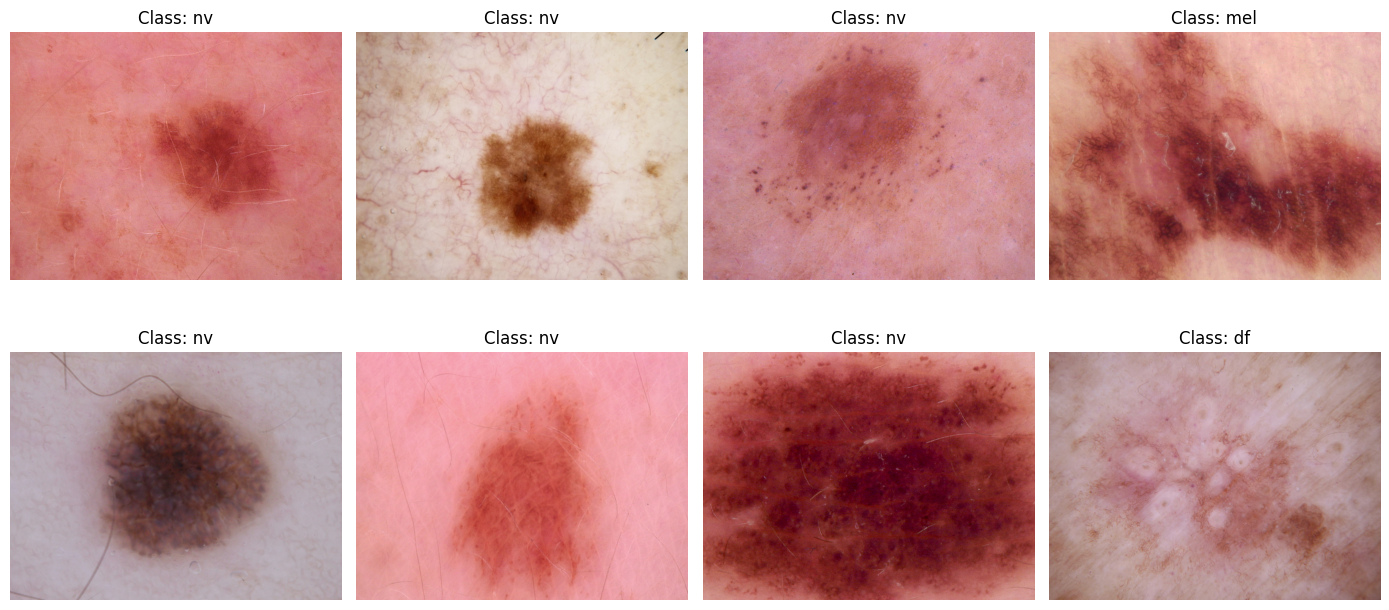

In [ ]:
# Assert that group IDs do not overlap between splits (preventing data leakage)
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

assert train_groups.isdisjoint(val_groups), "Leakage detected between Train and Validation!"
assert train_groups.isdisjoint(test_groups), "Leakage detected between Train and Test!"
assert val_groups.isdisjoint(test_groups), "Leakage detected between Validation and Test!"
print("Verification passed: No group overlap detected across splits!")

# Display class distribution breakdown per split
split_summary = pd.DataFrame({
    "Train": train_df["dx"].value_counts(),
    "Validation": val_df["dx"].value_counts(),
    "Test": test_df["dx"].value_counts()
}).fillna(0).astype(int)

print("\nClass distribution summary:")
print(split_summary)

# Plot a small grid of random training images with their diagnostic labels
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
samples = train_df.sample(min(8, len(train_df)), random_state=SEED)

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"Class: {row['dx']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Install timm for pre-built transformer backbones if not already present
!pip install -q timm

import torch
import torch.nn as nn
import timm

print("Libraries for model architecture loaded successfully!")
print(f"PyTorch version: {torch.__version__}")

Libraries for model architecture loaded successfully!
PyTorch version: 2.11.0+cu130


In [ ]:
class MultimodalSwinModel(nn.Module):
    def __init__(self, num_classes=7, metadata_dim=15):
        super(MultimodalSwinModel, self).__init__()

        # 1. Image Feature Extractor Branch (Swin-Tiny Transformer backbone)
        # Setting num_classes=0 removes the original ImageNet head and returns global image features [Batch, 768]
        self.image_encoder = timm.create_model(
            'swin_tiny_patch4_window7_224',
            pretrained=True,
            num_classes=0
        )
        img_feature_dim = self.image_encoder.num_features # Typically 768 for swin_tiny

        # 2. Metadata Feature Encoder Branch (Multi-Layer Perceptron / MLP)
        # Processes structured clinical features (age, sex, localization) through dense layers
        self.metadata_encoder = nn.Sequential(
            nn.Linear(metadata_dim, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.3),
            nn.Linear(64, 64),
            nn.ReLU()
        )

        # 3. Feature Fusion & Classification Head
        # Concatenates image features [Batch, 768] and metadata features [Batch, 64] = [Batch, 832]
        combined_dim = img_feature_dim + 64

        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, images, metadata):
        # Step A: Extract visual feature vector from the image branch
        img_feats = self.image_encoder(images)

        # Step B: Extract structured feature vector from the metadata branch
        meta_feats = self.metadata_encoder(metadata)

        # Step C: Concatenate both feature representations along the feature dimension
        combined = torch.cat((img_feats, meta_feats), dim=1)

        # Step D: Pass through classification head to get final class prediction logits
        logits = self.classifier(combined)
        return logits

# Initialize the model and move it to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note: Ensure metadata_dim matches the total feature columns outputted by your metadata preprocessor
model = MultimodalSwinModel(num_classes=7, metadata_dim=21).to(device)
# Initialize the model dynamically so you never have to hardcode a number again
#model = MultimodalSwinModel(num_classes=7, metadata_dim=X_train_meta.shape[1]).to(device)

print(f"Multimodal Swin Model initialized successfully and moved to: {device}")

Multimodal Swin Model initialized successfully and moved to: cuda


In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as transforms

# Define image augmentation pipelines as specified in the paper (Table II)
train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Simple tabular preprocessor for metadata (Age scaling + Sex/Localization one-hot encoding)
class MetadataPreprocessor:
    def __init__(self):
        self.age_mean = None
        self.age_std = None
        self.columns = None

    def fit_transform(self, df):
        df = df.copy()
        # Impute age with median and scale roughly to [0, 1] range or standardize
        self.age_median = df["age"].median()
        df["age"] = df["age"].fillna(self.age_median)
        self.age_max = df["age"].max() if df["age"].max() > 0 else 1.0
        df["age_scaled"] = df["age"] / self.age_max

        # One-hot encode categorical features (sex, localization)
        encoded_df = pd.get_dummies(df[["age_scaled", "sex", "localization"]], dummy_na=True)
        self.columns = encoded_df.columns
        return encoded_df.values.astype("float32")

    def transform(self, df):
        df = df.copy()
        df["age"] = df["age"].fillna(self.age_median)
        df["age_scaled"] = df["age"] / self.age_max
        encoded_df = pd.get_dummies(df[["age_scaled", "sex", "localization"]], dummy_na=True)
        # Reindex to match training columns exactly
        encoded_df = encoded_df.reindex(columns=self.columns, fill_value=0)
        return encoded_df.values.astype("float32")

# Instantiate and prepare tabular metadata matrices
meta_preprocessor = MetadataPreprocessor()
X_train_meta = meta_preprocessor.fit_transform(train_df)
X_val_meta = meta_preprocessor.transform(val_df)
X_test_meta = meta_preprocessor.transform(test_df)

# Map string labels to integers (0 to 6)
label_mapping = {val: idx for idx, val in enumerate(sorted(train_df["dx"].unique()))}
print("Label mapping:", label_mapping)

train_labels = train_df["dx"].map(label_mapping).values
val_labels = val_df["dx"].map(label_mapping).values
test_labels = test_df["dx"].map(label_mapping).values

# Define the Custom Multimodal PyTorch Dataset Class
class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, metadata_matrix, labels, transform=None):
        self.image_paths = dataframe["image_path"].values
        self.metadata = metadata_matrix
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Load image
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        # Load metadata vector and label tensors
        meta = torch.tensor(self.metadata[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return image, meta, label

# Create the actual dataset instances used by your DataLoaders
train_dataset = SkinLesionDataset(train_df, X_train_meta, train_labels, transform=train_transforms)
val_dataset = SkinLesionDataset(val_df, X_val_meta, val_labels, transform=val_test_transforms)
test_dataset = SkinLesionDataset(test_df, X_test_meta, test_labels, transform=val_test_transforms)

# Dynamically update metadata_dim for your model architecture
metadata_dim = X_train_meta.shape[1]
print(f"Metadata feature dimension successfully prepared: {metadata_dim}")

Label mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Metadata feature dimension successfully prepared: 21


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# 1. Set up DataLoaders
BATCH_SIZE = 32
NUM_WORKERS = 2

# (Ensure train_dataset and val_dataset are defined from your dataset loader)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# 2. Compute Class Weights for imbalance mitigation
class_counts = train_df["dx"].value_counts().sort_index().values
class_weights = torch.tensor(class_counts.sum() / (len(class_counts) * class_counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# 3. Optimizer and Scheduler setup matching paper specifications
optimizer = optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=95)
scaler = torch.cuda.amp.GradScaler()

num_epochs = 95  # Increase up to 95 for full paper convergence if time permits
print(f"Starting training loop for {num_epochs} epochs...\n")

for epoch in range(num_epochs):
    model.train()
    running_loss, correct_preds, total_preds = 0.0, 0, 0

    for images, metadata, labels in train_loader:
        images, metadata, labels = images.to(device), metadata.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = model(images, metadata)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_preds += (preds == labels).sum().item()
        total_preds += labels.size(0)

    scheduler.step()
    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {running_loss/total_preds:.4f} | Acc: {correct_preds/total_preds*100:.2f}%")

print("\nTraining completed successfully!")

Starting training loop for 95 epochs...



/tmp/ipykernel_10406/2354822554.py:22: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_10406/2354822554.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/95] | Loss: 1.6040 | Acc: 50.97%
Epoch [2/95] | Loss: 1.0403 | Acc: 65.83%
Epoch [3/95] | Loss: 0.8463 | Acc: 69.72%
Epoch [4/95] | Loss: 0.7327 | Acc: 72.23%
Epoch [5/95] | Loss: 0.6077 | Acc: 74.52%
Epoch [6/95] | Loss: 0.5342 | Acc: 76.77%
Epoch [7/95] | Loss: 0.4810 | Acc: 78.81%
Epoch [8/95] | Loss: 0.4531 | Acc: 80.50%
Epoch [9/95] | Loss: 0.3971 | Acc: 81.25%
Epoch [10/95] | Loss: 0.3777 | Acc: 83.17%
Epoch [11/95] | Loss: 0.3280 | Acc: 84.48%
Epoch [12/95] | Loss: 0.3010 | Acc: 86.33%
Epoch [13/95] | Loss: 0.2740 | Acc: 87.48%
Epoch [14/95] | Loss: 0.2721 | Acc: 87.53%
Epoch [15/95] | Loss: 0.2283 | Acc: 88.69%
Epoch [16/95] | Loss: 0.2153 | Acc: 89.20%
Epoch [17/95] | Loss: 0.1851 | Acc: 90.97%
Epoch [18/95] | Loss: 0.1872 | Acc: 90.75%
Epoch [19/95] | Loss: 0.1728 | Acc: 91.39%
Epoch [20/95] | Loss: 0.1498 | Acc: 92.27%
Epoch [21/95] | Loss: 0.1477 | Acc: 93.27%
Epoch [22/95] | Loss: 0.1640 | Acc: 93.83%
Epoch [23/95] | Loss: 0.1080 | Acc: 94.88%
Epoch [24/95] | Loss

In [ ]:
from torch.utils.data import DataLoader

# 1. Transform and prepare test metadata if not already done
X_test_meta = meta_preprocessor.transform(test_df)
test_labels = test_df["dx"].map(label_mapping).values

# 2. Instantiate the Test Dataset and DataLoader
test_dataset = SkinLesionDataset(test_df, X_test_meta, test_labels, transform=val_test_transforms)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("test_loader created successfully!")

test_loader created successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, metadata, labels in test_loader:
        images, metadata = images.to(device), metadata.to(device)
        with torch.cuda.amp.autocast():
            outputs = model(images, metadata)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

acc = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average='macro')
class_names_list = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

print(f"Test Accuracy:  {acc * 100:.2f}%")
print(f"Macro F1-Score: {macro_f1 * 100:.2f}%\n")
print("Detailed Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names_list))

/tmp/ipykernel_10406/3473824725.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Test Accuracy:  85.40%
Macro F1-Score: 71.83%

Detailed Classification Report:
              precision    recall  f1-score   support

       akiec       0.55      0.75      0.64        68
         bcc       0.75      0.82      0.78       100
         bkl       0.82      0.62      0.71       205
          df       0.82      0.41      0.55        22
         mel       0.69      0.50      0.58       222
          nv       0.90      0.96      0.93      1363
        vasc       0.93      0.76      0.84        34

    accuracy                           0.85      2014
   macro avg       0.78      0.69      0.72      2014
weighted avg       0.85      0.85      0.85      2014



In [ ]:
model.eval()
val_logits_list, val_labels_list = [], []

with torch.no_grad():
    for images, metadata, labels in val_loader:
        images, metadata = images.to(device), metadata.to(device)
        outputs = model(images, metadata)
        val_logits_list.append(outputs.cpu())
        val_labels_list.append(labels)

val_logits = torch.cat(val_logits_list).to(device)
val_labels_tensor = torch.cat(val_labels_list).to(device)

log_temperature = nn.Parameter(torch.zeros(1, device=device))
temperature_optimizer = torch.optim.LBFGS([log_temperature], lr=0.01, max_iter=100)
calibration_criterion = nn.CrossEntropyLoss()

def temperature_closure():
    temperature_optimizer.zero_grad()
    loss = calibration_criterion(val_logits / torch.exp(log_temperature), val_labels_tensor)
    loss.backward()
    return loss

temperature_optimizer.step(temperature_closure)
learned_temperature = torch.exp(log_temperature.detach()).item()

print(f"Optimal Temperature (T) learned: {learned_temperature:.4f}")
print("Model pipeline finalized successfully!")

Optimal Temperature (T) learned: 2.4394
Model pipeline finalized successfully!
